# Stock Market Analysis & LSTM Price Prediction

**Goal:** analyse recent price behaviour of four large tech stocks (AAPL, GOOG, MSFT, AMZN) and train an LSTM network to predict the next-day closing price of one stock.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, yfinance, scikit-learn, TensorFlow/Keras.

**Questions answered**
1. How did the price and trading volume change over time?
2. What do the 10/20/50-day moving averages show?
3. What were the daily returns?
4. How correlated are the stocks with each other?
5. How much risk (volatility) does each stock carry versus its expected return?
6. Can an LSTM predict the next closing price, and does it beat a naive baseline?

**Data:** Yahoo Finance via `yfinance`.

## Getting the data
Data is downloaded directly from Yahoo Finance with `yfinance` (last 12 months for the analysis sections, daily data from 2012 for the LSTM).

# 1. How did the price change over time?
Price and trading volume history of each stock over the last 12 months.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.style.use("fivethirtyeight")
%matplotlib inline

# For reading stock data from yahoo
import yfinance as yf


# For time stamps
from datetime import datetime


# The tech stocks we'll use for this analysis
tech_list = ['AAPL', 'GOOG', 'MSFT', 'AMZN']

# Set up End and Start times for data grab
end = datetime.now()
start = datetime(end.year - 1, end.month, end.day)

for stock in tech_list:
    globals()[stock] = yf.download(stock, start=start, end=end,
                                   auto_adjust=False, multi_level_index=False)
    

company_list = [AAPL, GOOG, MSFT, AMZN]
company_name = ["APPLE", "GOOGLE", "MICROSOFT", "AMAZON"]

for company, com_name in zip(company_list, company_name):
    company["company_name"] = com_name
    
df = pd.concat(company_list, axis=0)
df.tail(10)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume,company_name
Date,,,,,,,
2026-10-07,259.920013,259.920013,260.140015,253.169998,254.229996,36225800,AMAZON
2026-10-08,254.059998,254.059998,259.859985,253.779999,259.739990,38649900,AMAZON
2026-10-09,262.429993,262.429993,262.799988,256.000000,256.500000,34770000,AMAZON
2026-10-12,259.529999,259.529999,263.700012,259.269989,262.500000,26577900,AMAZON
2026-10-13,258.579987,258.579987,262.839996,258.420013,259.440002,25299500,AMAZON
2026-10-14,254.080002,254.080002,259.649994,252.660004,258.010010,34821000,AMAZON
2026-10-15,254.759995,254.759995,255.600006,248.649994,250.889999,34564200,AMAZON
2026-10-16,250.000000,250.000000,255.539993,248.600006,255.100006,40427300,AMAZON
2026-10-19,262.450012,262.450012,263.720001,255.220001,255.250000,56188800,AMAZON


The data is numeric and indexed by date. Weekends and market holidays are missing from the records.

## Descriptive statistics

In [2]:
# Summary statistics
AAPL.describe()

,Adj Close,Close,High,Low,Open,Volume
count,251.000000,251.000000,251.000000,251.000000,251.000000,2.510000e+02
mean,288.574627,288.990557,291.916057,285.901633,288.693665,4.782759e+07
std,28.479187,28.255374,28.438721,27.883217,27.995467,2.136559e+07
min,246.030319,246.630005,249.199997,243.419998,247.320007,1.791060e+07
25%,265.700836,266.214996,269.660004,263.135010,266.020004,3.707790e+07
50%,277.364990,278.119995,280.380005,276.149994,278.130005,4.367020e+07
75%,311.545547,311.679993,315.085007,308.824997,311.120010,5.114535e+07
max,343.459991,343.459991,348.149994,341.720001,346.950012,2.617755e+08


Each stock has 251 trading days in the last 12 months (weekends and holidays are excluded).

## Data info
Column types and non-null counts.

In [3]:
# General info
AAPL.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-10-21 to 2026-10-20
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Adj Close     251 non-null    float64
 1   Close         251 non-null    float64
 2   High          251 non-null    float64
 3   Low           251 non-null    float64
 4   Open          251 non-null    float64
 5   Volume        251 non-null    int64  
 6   company_name  251 non-null    str    
dtypes: float64(5), int64(1), str(1)
memory usage: 15.7 KB


## Closing price
The closing price is the last traded price of the day and the standard benchmark for tracking performance.

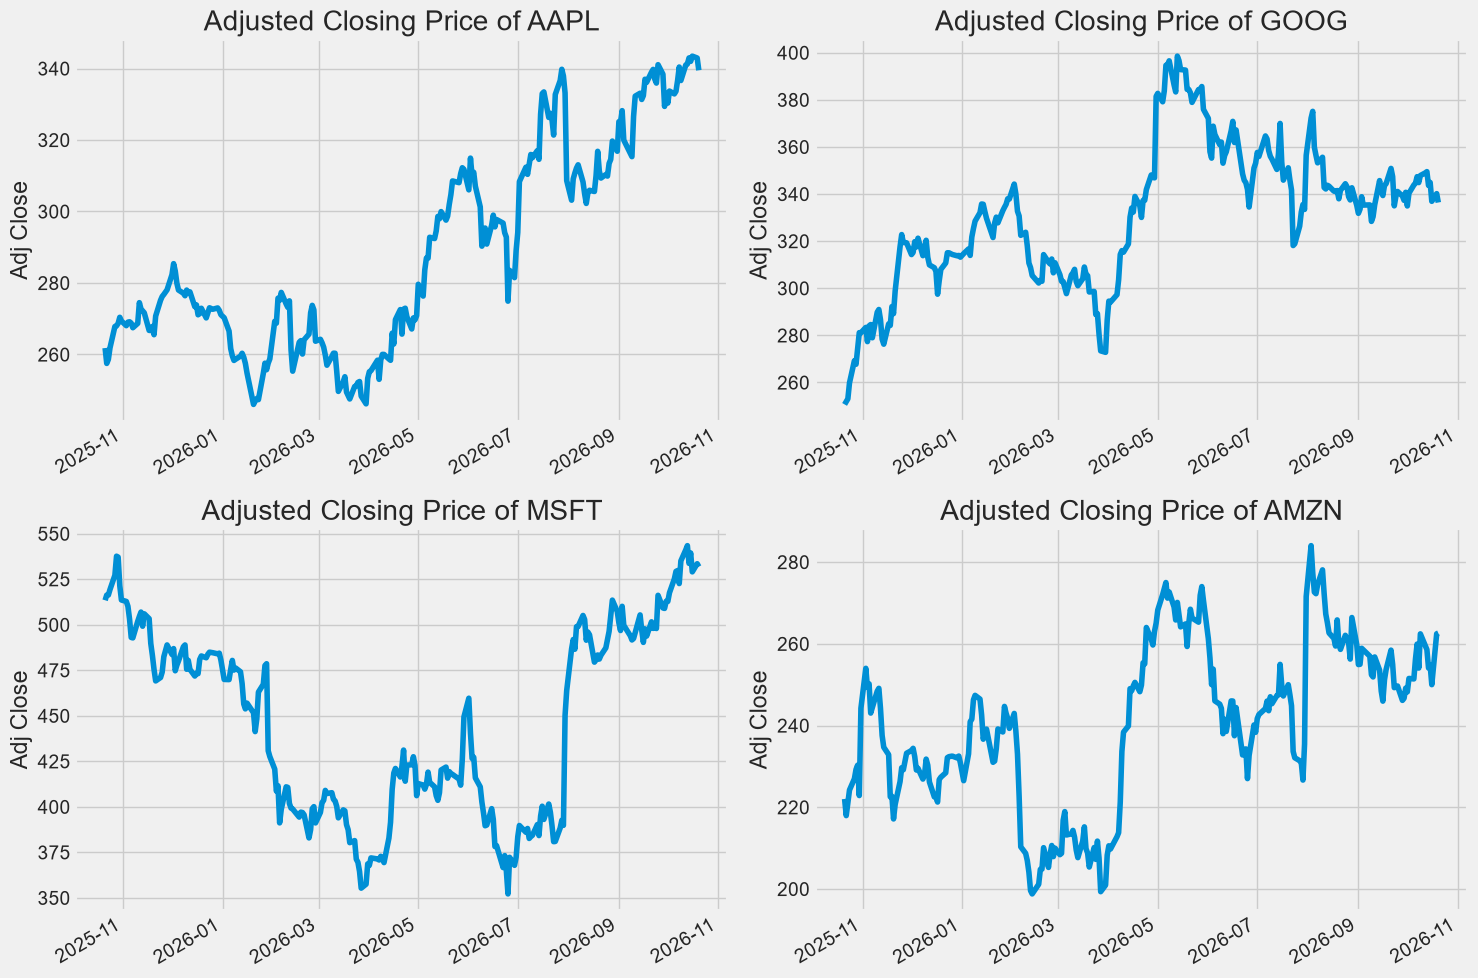

In [4]:
# Closing price history
plt.figure(figsize=(15, 10))
plt.subplots_adjust(top=1.25, bottom=1.2)

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Adj Close'].plot()
    plt.ylabel('Adj Close')
    plt.xlabel(None)
    plt.title(f"Adjusted Closing Price of {tech_list[i - 1]}")
    
plt.tight_layout()

## Trading volume
Volume is the number of shares traded each day.

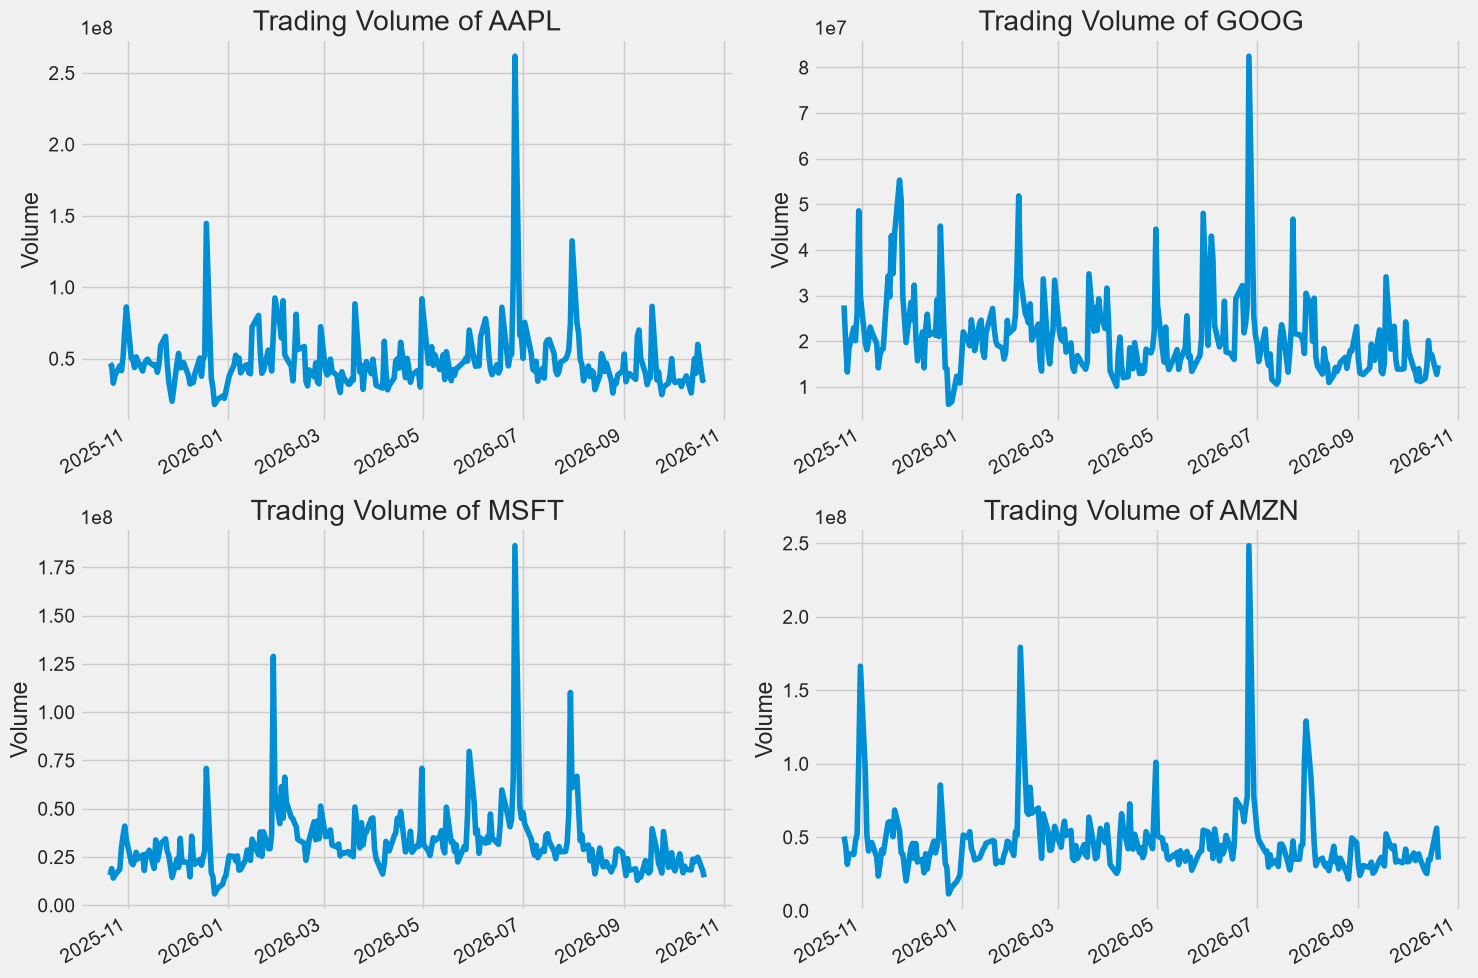

In [5]:
# Daily trading volume
plt.figure(figsize=(15, 10))
plt.subplots_adjust(top=1.25, bottom=1.2)

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Volume'].plot()
    plt.ylabel('Volume')
    plt.xlabel(None)
    plt.title(f"Trading Volume of {tech_list[i - 1]}")
    
plt.tight_layout()

Next, moving averages are used to smooth out the daily noise.

# 2. Moving averages
A moving average (MA) smooths the price by averaging it over a fixed window: 10, 20 and 50 days here.

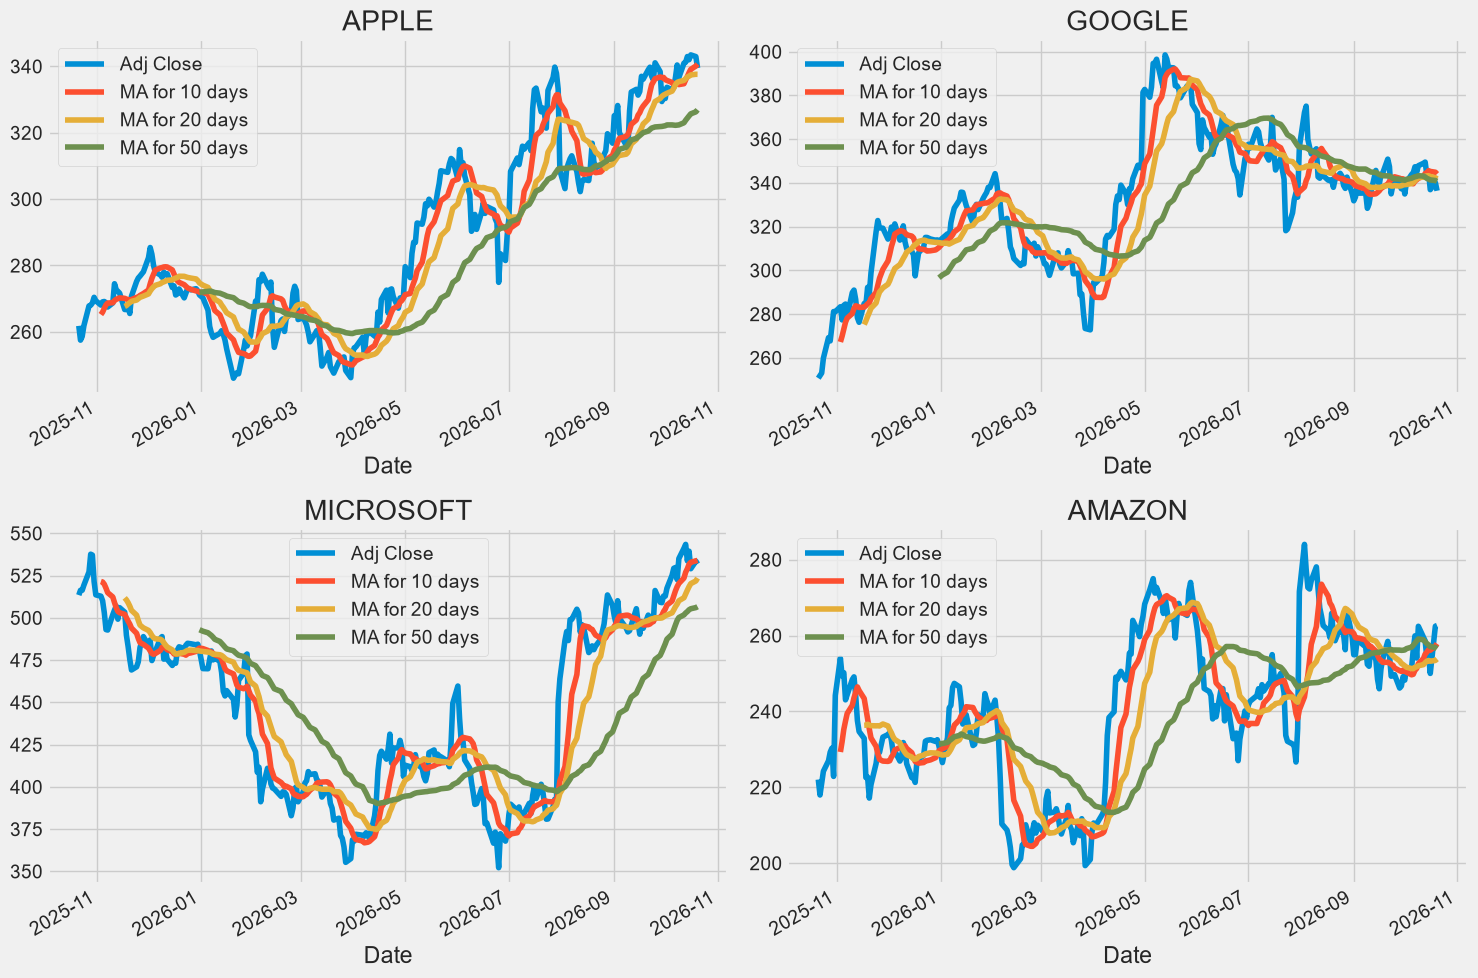

In [6]:
ma_day = [10, 20, 50]

for ma in ma_day:
    for company in company_list:
        column_name = f"MA for {ma} days"
        company[column_name] = company['Adj Close'].rolling(ma).mean()
        

fig, axes = plt.subplots(nrows=2, ncols=2)
fig.set_figheight(10)
fig.set_figwidth(15)

AAPL[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[0,0])
axes[0,0].set_title('APPLE')

GOOG[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[0,1])
axes[0,1].set_title('GOOGLE')

MSFT[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[1,0])
axes[1,0].set_title('MICROSOFT')

AMZN[['Adj Close', 'MA for 10 days', 'MA for 20 days', 'MA for 50 days']].plot(ax=axes[1,1])
axes[1,1].set_title('AMAZON')

fig.tight_layout()

The 10- and 20-day averages follow the price closely while removing day-to-day noise. The 50-day average is smoother and lags further behind.

# 3. Daily returns

The daily return is the percentage change of the price from the previous day. It describes risk more directly than the price level.

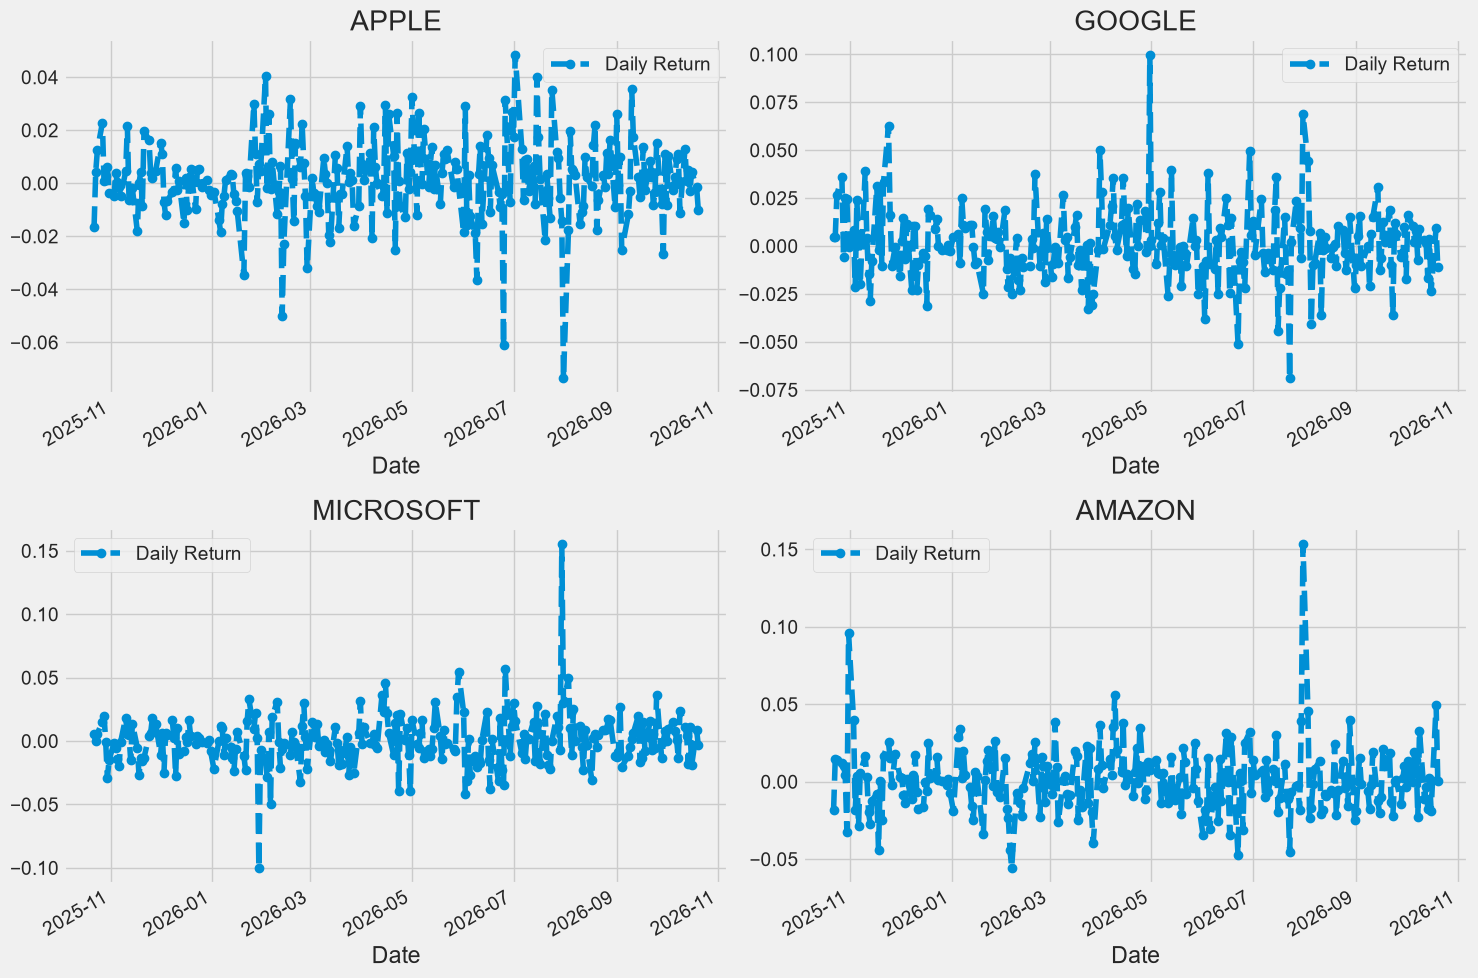

In [7]:
# Daily return = percentage change of the adjusted close
for company in company_list:
    company['Daily Return'] = company['Adj Close'].pct_change()

# Then we'll plot the daily return percentage
fig, axes = plt.subplots(nrows=2, ncols=2)
fig.set_figheight(10)
fig.set_figwidth(15)

AAPL['Daily Return'].plot(ax=axes[0,0], legend=True, linestyle='--', marker='o')
axes[0,0].set_title('APPLE')

GOOG['Daily Return'].plot(ax=axes[0,1], legend=True, linestyle='--', marker='o')
axes[0,1].set_title('GOOGLE')

MSFT['Daily Return'].plot(ax=axes[1,0], legend=True, linestyle='--', marker='o')
axes[1,0].set_title('MICROSOFT')

AMZN['Daily Return'].plot(ax=axes[1,1], legend=True, linestyle='--', marker='o')
axes[1,1].set_title('AMAZON')

fig.tight_layout()

Histograms show how the daily returns are distributed around zero.

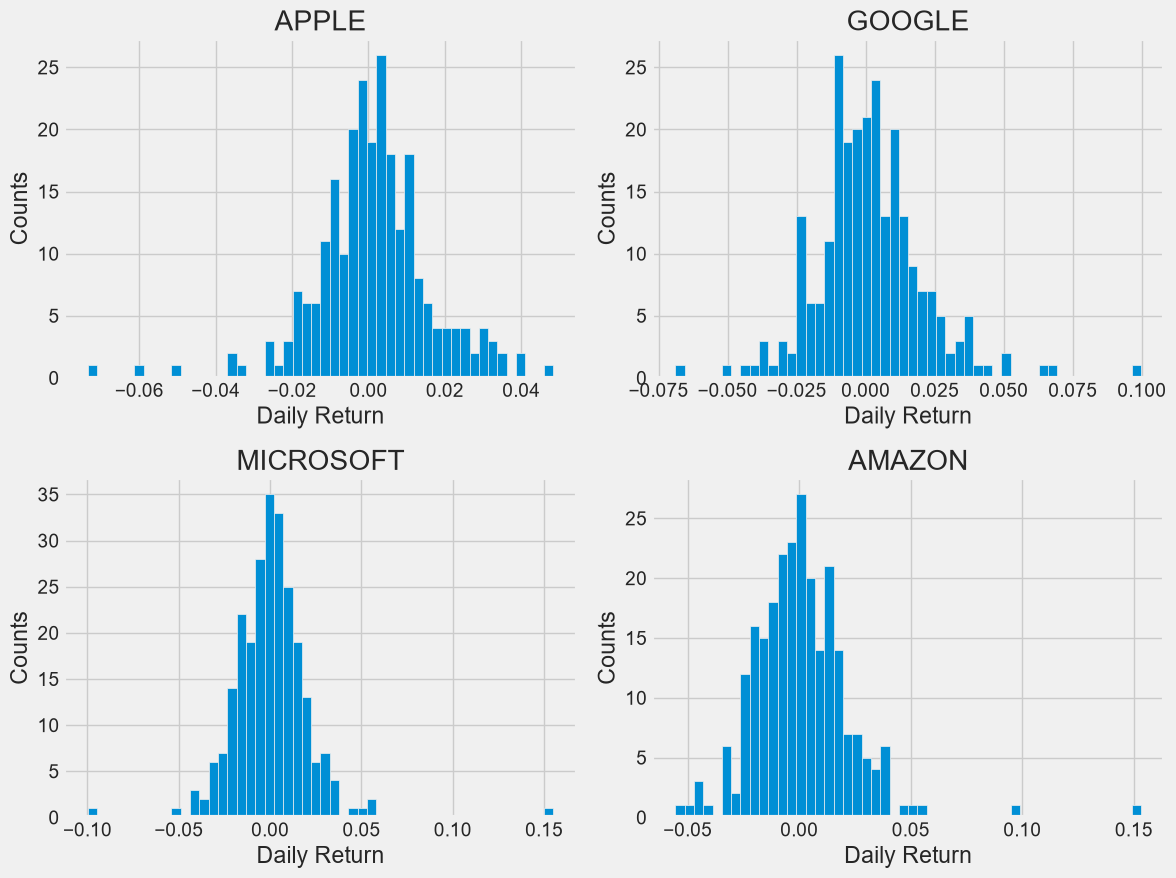

In [8]:
plt.figure(figsize=(12, 9))

for i, company in enumerate(company_list, 1):
    plt.subplot(2, 2, i)
    company['Daily Return'].hist(bins=50)
    plt.xlabel('Daily Return')
    plt.ylabel('Counts')
    plt.title(f'{company_name[i - 1]}')
    
plt.tight_layout()

# 4. Correlation between the stocks

Correlation measures how closely two series move together (from -1 to +1). It does not show causation. The adjusted closing prices of all four stocks are put into one DataFrame to compare them.

In [32]:
# Adjusted closing prices of all four stocks in one DataFrame

closing_df = yf.download(tech_list, start=start, end=end, auto_adjust=False)['Adj Close']

# Make a new tech returns DataFrame
tech_rets = closing_df.pct_change()
tech_rets.head()

[*********************100%***********************]  3 of 4 completed


Ticker,AAPL,AMZN,GOOG,MSFT
Date,,,,
2025-10-21,NaN,NaN,NaN,NaN
2025-10-22,-0.016440,-0.018376,0.004735,0.005563
2025-10-23,0.004372,0.014407,0.004752,0.000038
2025-10-24,0.012482,0.014112,0.026721,0.005859
2025-10-27,0.022791,0.012310,0.036160,0.015107


A stock compared with itself gives a perfect straight line (correlation = 1).

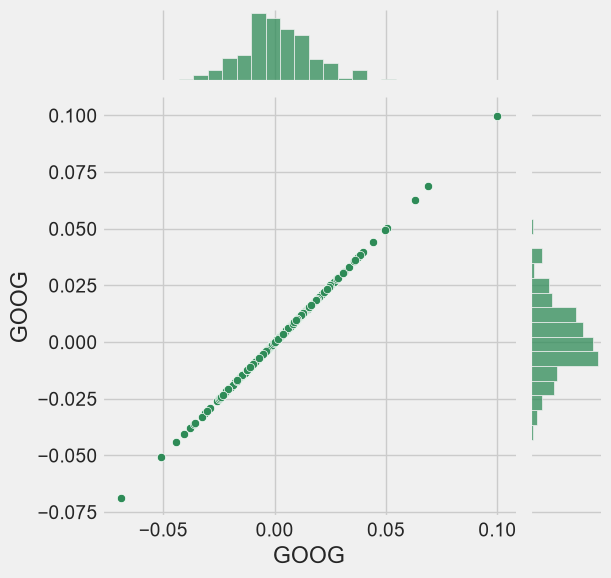

In [33]:
# GOOG vs itself: perfect linear relationship (sanity check)
sns.jointplot(x='GOOG', y='GOOG', data=tech_rets, kind='scatter', color='seagreen')

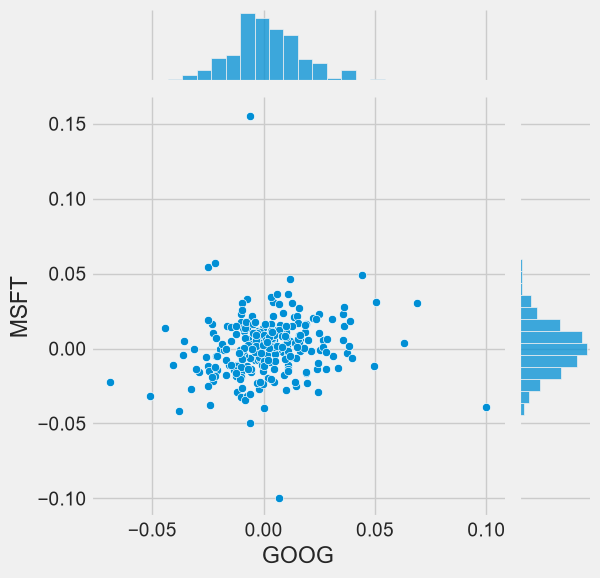

In [34]:
# Daily returns: GOOG vs MSFT
sns.jointplot(x='GOOG', y='MSFT', data=tech_rets, kind='scatter')

If the daily returns of two stocks are strongly positively correlated, their scatter plot shows an upward linear pattern. `sns.pairplot()` repeats this comparison for every pair of stocks.

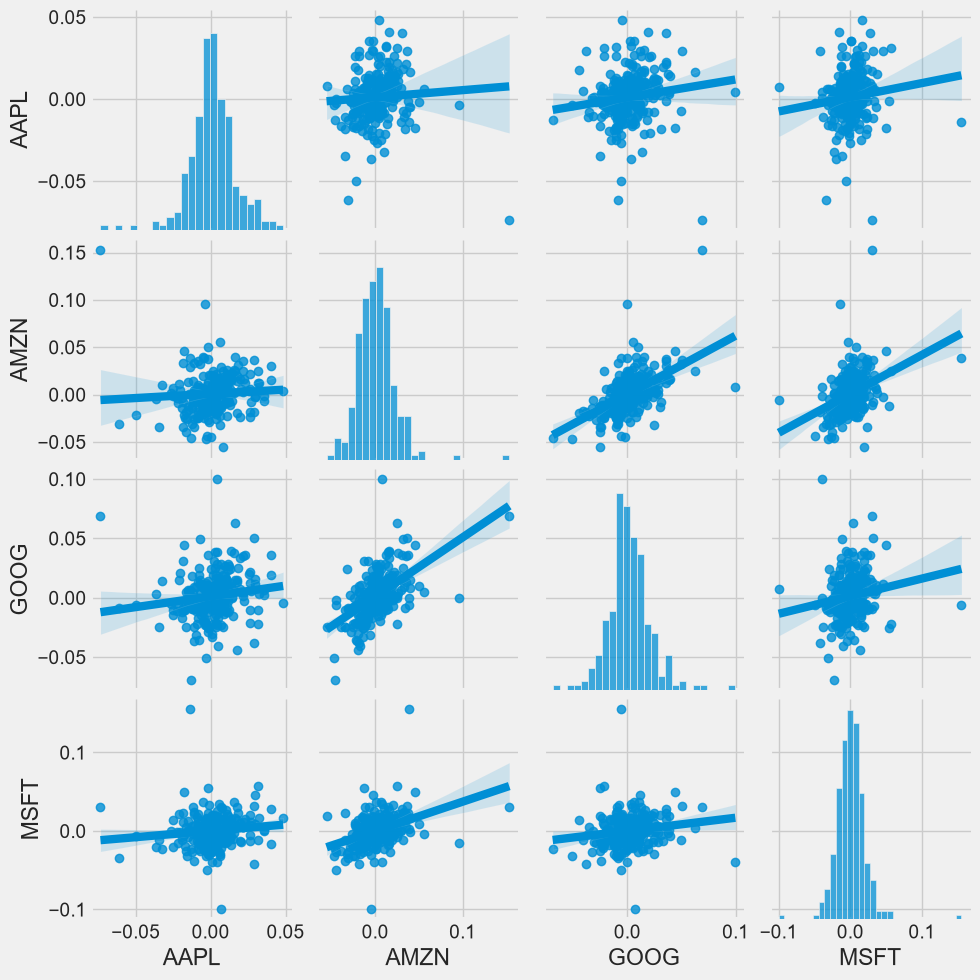

In [35]:
# Pairwise scatter plots of daily returns

sns.pairplot(tech_rets, kind='reg')

In the pair plots, GOOG and AMZN show the clearest linear relationship in daily returns. `sns.PairGrid()` gives more control over the layout: scatter plots above the diagonal, KDE plots below and histograms on the diagonal.

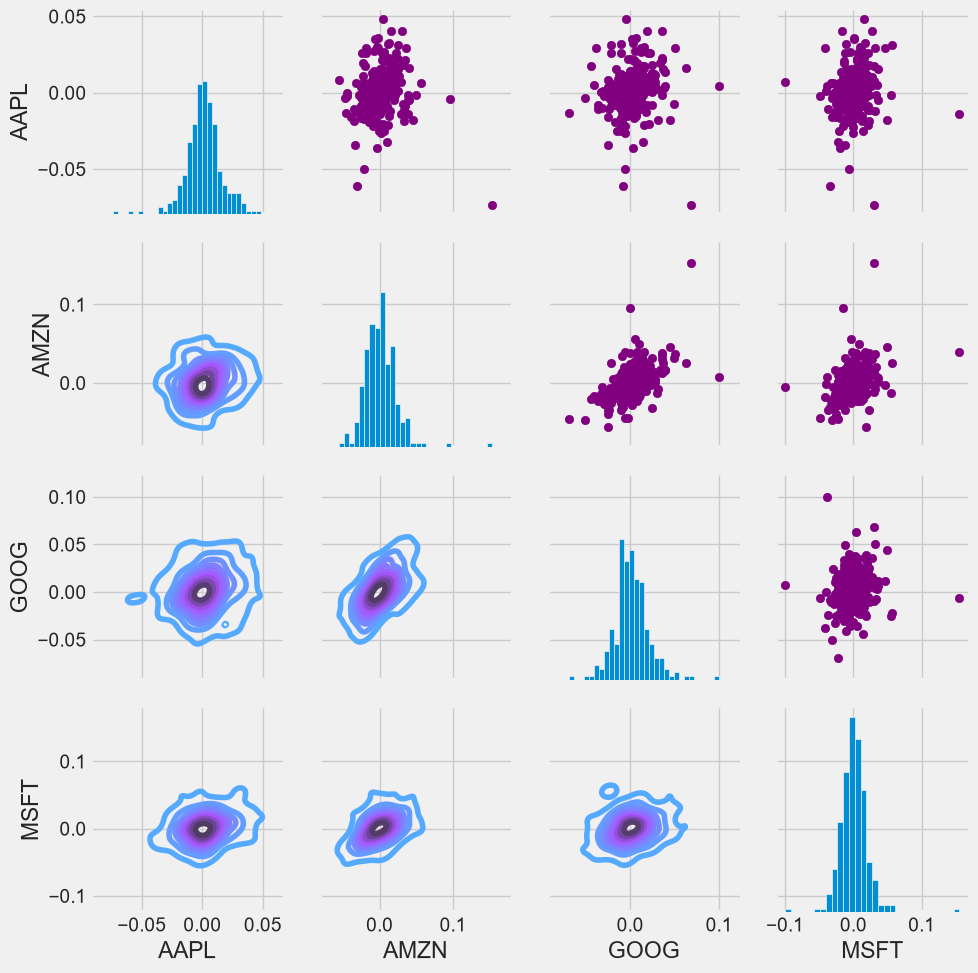

In [36]:
# Pair grid of daily returns: scatter (upper), KDE (lower), histogram (diagonal)
return_fig = sns.PairGrid(tech_rets.dropna())

# Using map_upper we can specify what the upper triangle will look like.
return_fig.map_upper(plt.scatter, color='purple')

# We can also define the lower triangle in the figure, inclufing the plot type (kde) 
# or the color map (BluePurple)
return_fig.map_lower(sns.kdeplot, cmap='cool_d')

# Finally we'll define the diagonal as a series of histogram plots of the daily return
return_fig.map_diag(plt.hist, bins=30)

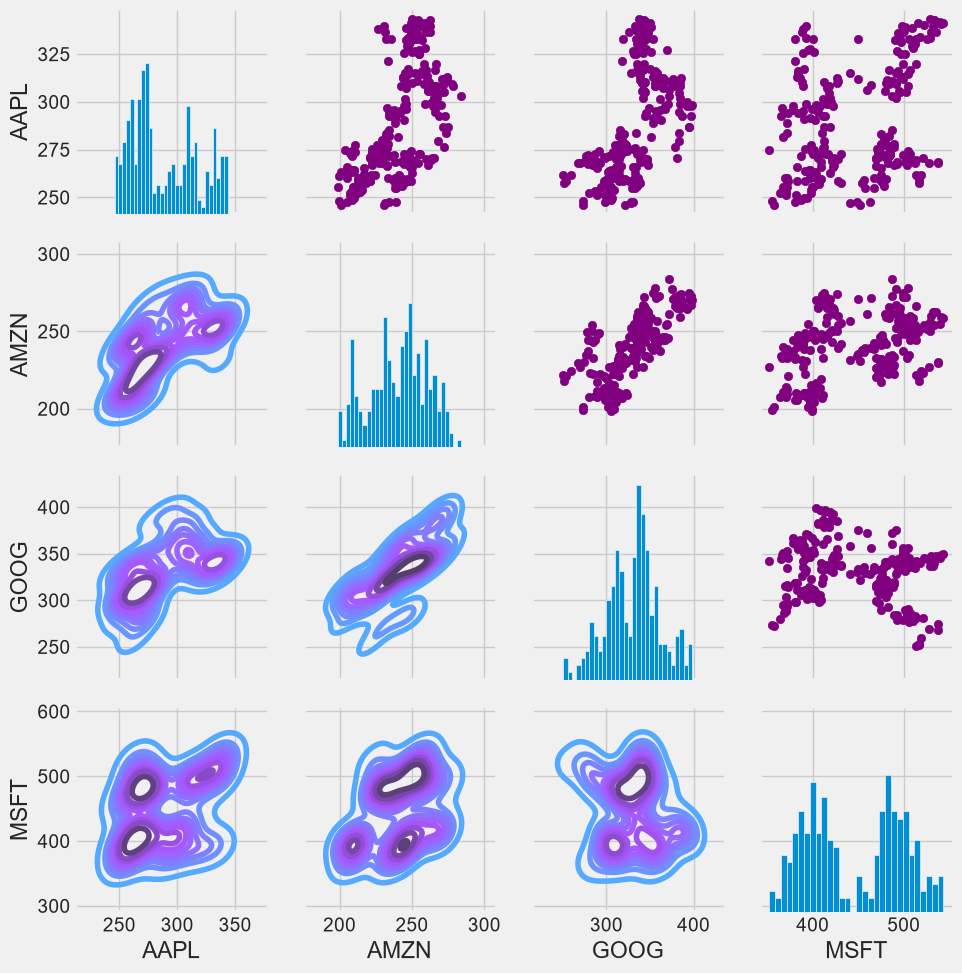

In [37]:
# Pair grid of closing prices, same layout
returns_fig = sns.PairGrid(closing_df)

# Using map_upper we can specify what the upper triangle will look like.
returns_fig.map_upper(plt.scatter,color='purple')

# We can also define the lower triangle in the figure, inclufing the plot type (kde) or the color map (BluePurple)
returns_fig.map_lower(sns.kdeplot,cmap='cool_d')

# Finally we'll define the diagonal as a series of histogram plots of the daily return
returns_fig.map_diag(plt.hist,bins=30)

Correlation heatmaps give the exact values for daily returns (left) and closing prices (right).

Text(0.5, 1.0, 'Correlation of stock closing price')

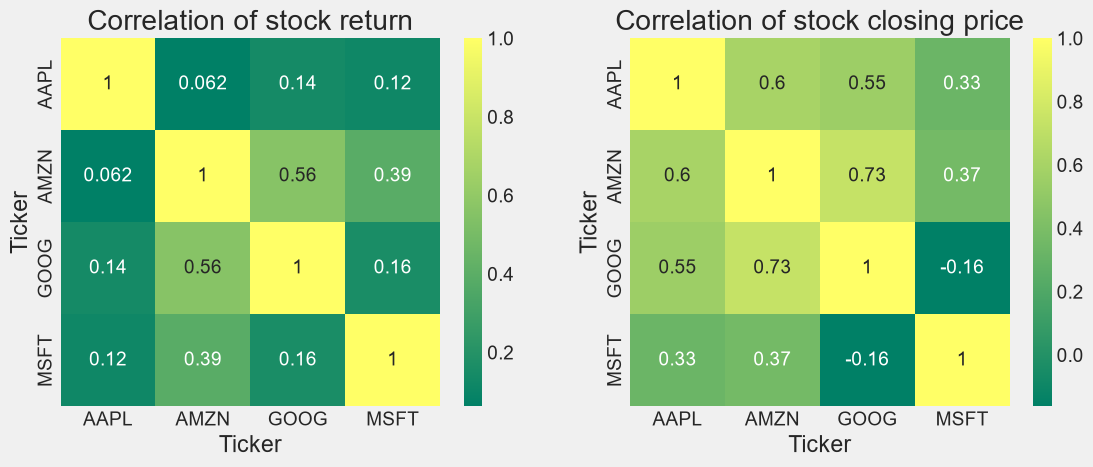

In [38]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
sns.heatmap(tech_rets.corr(), annot=True, cmap='summer')
plt.title('Correlation of stock return')

plt.subplot(2, 2, 2)
sns.heatmap(closing_df.corr(), annot=True, cmap='summer')
plt.title('Correlation of stock closing price')

- Daily returns of all four stocks are positively correlated. The strongest pairs are AMZN–GOOG (0.56) and AMZN–MSFT (0.39); AAPL is the least correlated with the others (0.06–0.14).
- Closing prices show a different picture: AMZN–GOOG is highest (0.73) and MSFT–GOOG is negative (-0.16). Price-level correlations are less reliable than return correlations because any two trending series can look correlated.
- Moderate return correlations mean holding these stocks together gives some diversification.

# 5. Risk vs expected return

A simple way to measure risk is to compare each stock's expected (mean) daily return with the standard deviation of its daily returns.

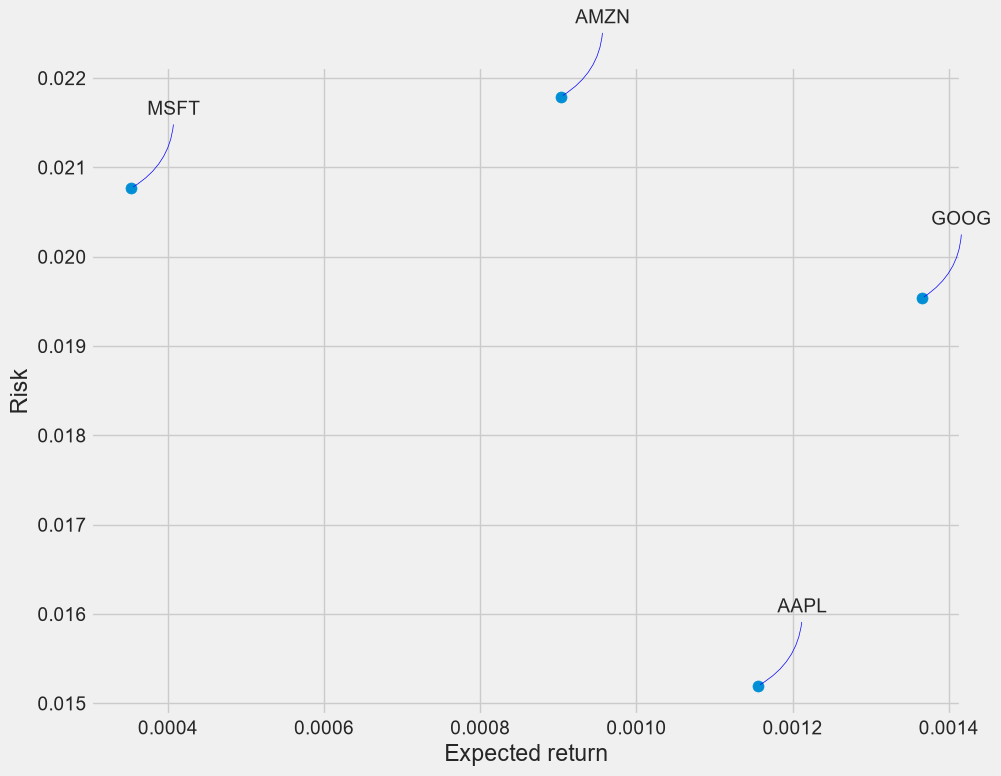

In [16]:
rets = tech_rets.dropna()

area = np.pi * 20

plt.figure(figsize=(10, 8))
plt.scatter(rets.mean(), rets.std(), s=area)
plt.xlabel('Expected return')
plt.ylabel('Risk')

for label, x, y in zip(rets.columns, rets.mean(), rets.std()):
    plt.annotate(label, xy=(x, y), xytext=(50, 50), textcoords='offset points', ha='right', va='bottom', 
                 arrowprops=dict(arrowstyle='-', color='blue', connectionstyle='arc3,rad=-0.3'))

**Reading the chart:** AAPL has the lowest risk and the second-highest expected return, so it gave the best return for the risk taken in this period. GOOG has the highest expected return with moderate risk. AMZN carries the most risk, and MSFT has the lowest expected return.

## Extra analysis: relative performance, volatility and Bollinger Bands
The next three charts show which stock gained the most, how its risk changed over time, and how far price moves away from its recent average.

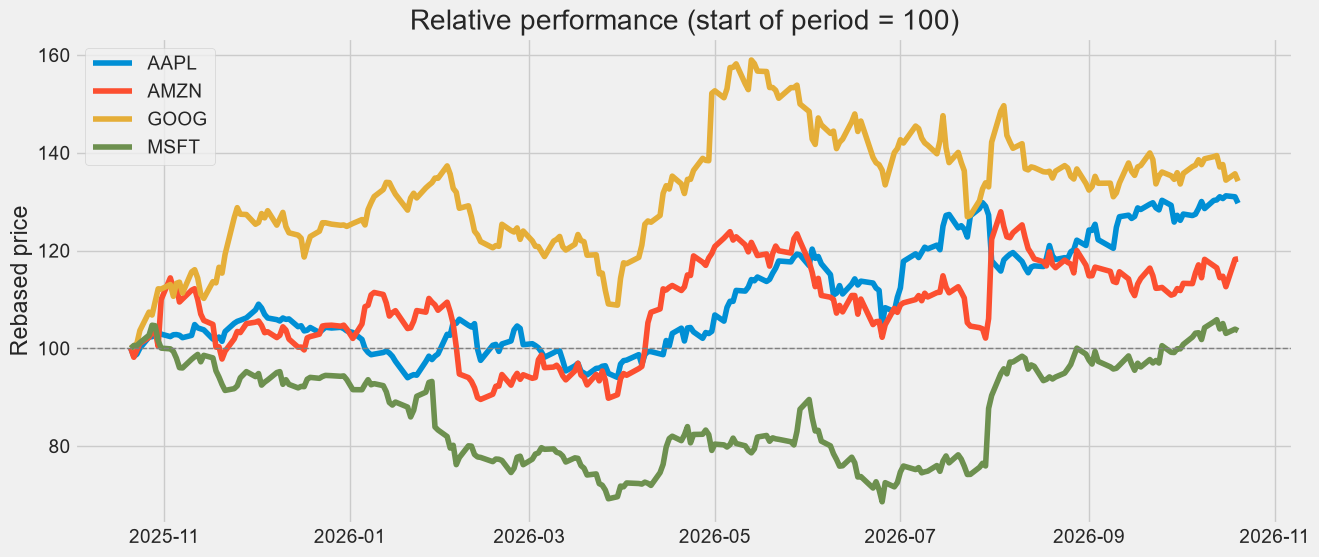

Total return over the period (%):
Ticker
GOOG    34.2
AAPL    29.7
AMZN    18.3
MSFT     3.6
Name: 2026-10-20 00:00:00, dtype: float64


In [17]:
# Rebase every stock to 100 at the start of the period
rebased = closing_df / closing_df.iloc[0] * 100

plt.figure(figsize=(14, 6))
for col in rebased.columns:
    plt.plot(rebased.index, rebased[col], label=col)
plt.axhline(100, color='gray', linestyle='--', linewidth=1)
plt.title('Relative performance (start of period = 100)')
plt.ylabel('Rebased price')
plt.legend()
plt.show()

print("Total return over the period (%):")
print((rebased.iloc[-1] - 100).round(1).sort_values(ascending=False))

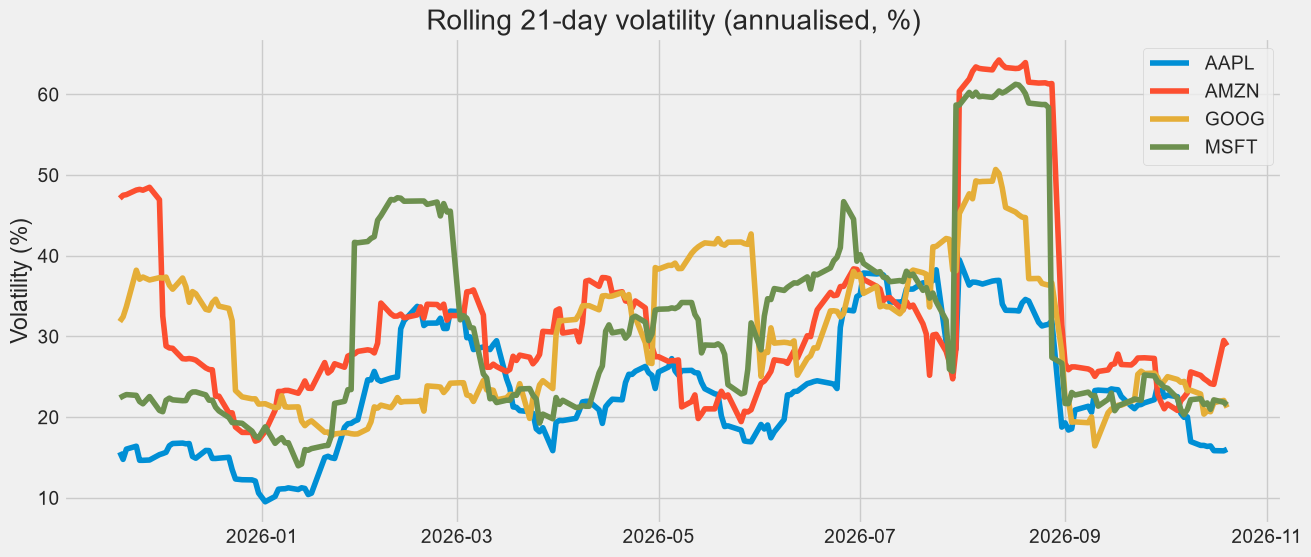

In [18]:
# 21-day rolling standard deviation of daily returns, annualised (x sqrt(252))
rolling_vol = tech_rets.rolling(21).std() * np.sqrt(252) * 100

plt.figure(figsize=(14, 6))
for col in rolling_vol.columns:
    plt.plot(rolling_vol.index, rolling_vol[col], label=col)
plt.title('Rolling 21-day volatility (annualised, %)')
plt.ylabel('Volatility (%)')
plt.legend()
plt.show()

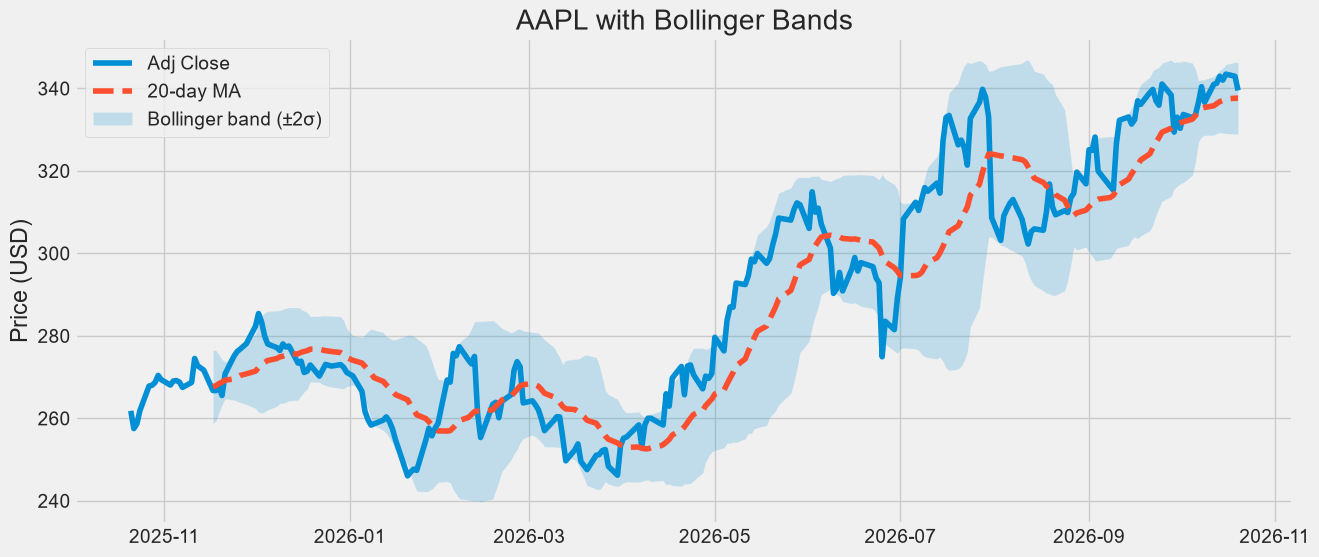

In [19]:
# Bollinger Bands for AAPL: 20-day moving average +/- 2 standard deviations
price = AAPL['Adj Close']
ma20 = price.rolling(20).mean()
std20 = price.rolling(20).std()

plt.figure(figsize=(14, 6))
plt.plot(price, label='Adj Close')
plt.plot(ma20, label='20-day MA', linestyle='--')
plt.fill_between(price.index, ma20 - 2 * std20, ma20 + 2 * std20, alpha=0.2, label='Bollinger band (±2σ)')
plt.title('AAPL with Bollinger Bands')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

# 6. Predicting with an LSTM
**Approach.** The first version of this model predicted the raw closing price. That has two problems: prices keep growing, so test prices fall outside the range the model saw in training, and "tomorrow = today" is already a very strong guess for a price. This version predicts the **next-day return** (% change) instead, which stays in a stable range over time.

- **Input:** the previous 60 trading days of 5 features: daily return, change in trading volume, distance from the 10-day and 20-day moving averages, and RSI(14).
- **Output:** tomorrow's return. It is converted back to a price with `price_tomorrow = price_today × (1 + predicted_return)`.
- **Split:** chronological, first 95% for training and last 5% for testing. Scalers are fitted on training rows only, so nothing from the test period leaks into training.

In [20]:
# Choose the stock to model (change this to try another ticker)
TICKER = 'AAPL'

# Daily price history from 2012 onwards
df = yf.download(TICKER, start='2012-01-01', end=datetime.now(),
                 auto_adjust=False, multi_level_index=False)
df

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2012-01-03,12.299734,14.686786,14.732143,14.607143,14.621429,302220800
2012-01-04,12.365838,14.765714,14.810000,14.617143,14.642857,260022000
2012-01-05,12.503121,14.929643,14.948214,14.738214,14.819643,271269600
2012-01-06,12.633833,15.085714,15.098214,14.972143,14.991786,318292800
2012-01-09,12.613791,15.061786,15.276786,15.048214,15.196429,394024400
...,...,...,...,...,...,...
2026-10-14,342.959991,342.959991,347.089996,341.720001,344.609985,50061100
2026-10-15,342.000000,342.000000,347.850006,341.600006,346.950012,39767300
2026-10-16,343.459991,343.459991,347.820007,340.459991,346.089996,59946400


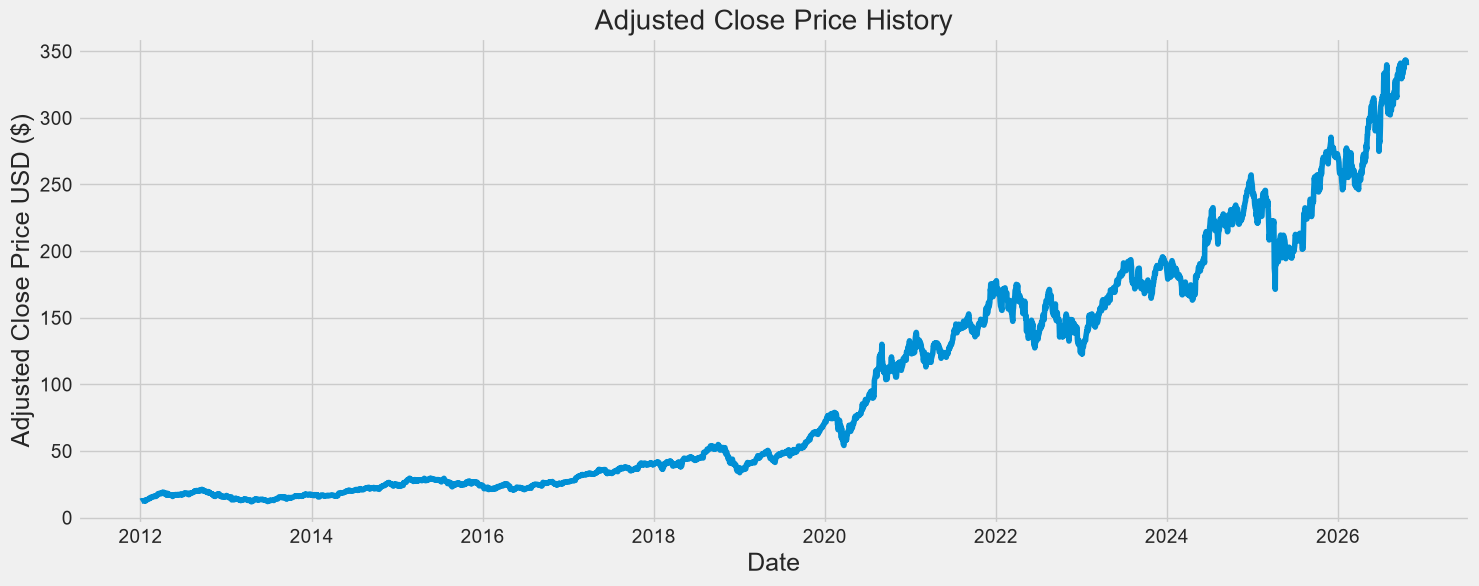

In [21]:
plt.figure(figsize=(16,6))
plt.title('Adjusted Close Price History')
plt.plot(df['Adj Close'])
plt.xlabel('Date', fontsize=18)
plt.ylabel('Adjusted Close Price USD ($)', fontsize=18)
plt.show()

## Step 1: Build the features
Every feature is computed from past data only. The target is the **next** day's return.

In [22]:
# Use the adjusted close everywhere so the whole notebook is consistent
px = df['Adj Close']

feat = pd.DataFrame(index=df.index)
feat['return'] = px.pct_change()                          # daily return
feat['volume_chg'] = np.log(df['Volume']).diff()          # change in trading volume
feat['ma10_gap'] = px / px.rolling(10).mean() - 1         # distance from 10-day moving average
feat['ma20_gap'] = px / px.rolling(20).mean() - 1         # distance from 20-day moving average

# RSI(14): momentum indicator, scaled to 0-1
delta = px.diff()
avg_gain = delta.clip(lower=0).rolling(14).mean()
avg_loss = (-delta.clip(upper=0)).rolling(14).mean()
feat['rsi'] = (100 - 100 / (1 + avg_gain / avg_loss)) / 100

# Target = NEXT day's return (what the model has to predict)
feat['target'] = feat['return'].shift(-1)

feat = feat.replace([np.inf, -np.inf], np.nan).dropna()
FEATURES = ['return', 'volume_chg', 'ma10_gap', 'ma20_gap', 'rsi']

print(feat.shape)
feat.tail()

(3701, 6)


,return,volume_chg,ma10_gap,ma20_gap,rsi,target
Date,,,,,,
2026-10-13,0.000880,0.408880,0.015830,0.014839,0.547914,0.004952
2026-10-14,0.004952,0.250098,0.017849,0.018267,0.578327,-0.002799
2026-10-15,-0.002799,-0.230199,0.011493,0.014664,0.511411,0.004269
2026-10-16,0.004269,0.410406,0.012884,0.017888,0.563986,-0.001514
2026-10-19,-0.001514,-0.550372,0.008362,0.015751,0.717966,-0.010031


## Step 2: Train/test split and scaling
The scaler learns its mean and standard deviation from the **training rows only**.

In [23]:
from sklearn.preprocessing import StandardScaler

WINDOW = 60                           # days of history the model sees
split = int(len(feat) * 0.95)         # rows before this index = training period

scaler = StandardScaler().fit(feat[FEATURES].iloc[:split])
X_all = scaler.transform(feat[FEATURES])
y_all = feat['target'].values * 100   # next-day return in percent

print('Training rows:', split, '| Test rows:', len(feat) - split)

Training rows: 3515 | Test rows: 186


## Step 3: Create 60-day windows
Each sample is a block of 60 days of features, and its label is the return of the following day.

In [24]:
def make_windows(X, y, window, start, stop):
    """Window ending at row t uses rows t-window+1 ... t and predicts y[t] (the return of day t+1)."""
    xs, ys, rows = [], [], []
    for t in range(max(start, window - 1), stop):
        xs.append(X[t - window + 1: t + 1])
        ys.append(y[t])
        rows.append(t)
    return np.array(xs), np.array(ys), np.array(rows)

# Train: the label of the last training window must still lie inside the training period
x_train, y_train, _ = make_windows(X_all, y_all, WINDOW, 0, split - 1)
# Test: windows ending from the split onwards
x_test, y_test, test_rows = make_windows(X_all, y_all, WINDOW, split, len(feat))

print('x_train:', x_train.shape, '| x_test:', x_test.shape)

x_train: (3455, 60, 5) | x_test: (186, 60, 5)


## Step 4: Build and train the LSTM
Dropout reduces overfitting and early stopping ends training once the validation loss stops improving (the best weights are restored). The validation set is the last 10% of the training windows, in time order.

In [25]:
import keras
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)       # reproducible results

model = Sequential([
    Input(shape=(WINDOW, len(FEATURES))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error')

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history = model.fit(x_train, y_train, batch_size=32, epochs=60,
                    validation_split=0.1, callbacks=[early_stop], verbose=2)

Epoch 1/60
98/98 - 8s - 84ms/step - loss: 3.1576 - val_loss: 3.4155
Epoch 2/60
98/98 - 3s - 32ms/step - loss: 3.1648 - val_loss: 3.4206
Epoch 3/60
98/98 - 3s - 29ms/step - loss: 3.1546 - val_loss: 3.4172
Epoch 4/60
98/98 - 3s - 28ms/step - loss: 3.1466 - val_loss: 3.4173
Epoch 5/60
98/98 - 3s - 27ms/step - loss: 3.1465 - val_loss: 3.4063
Epoch 6/60
98/98 - 3s - 27ms/step - loss: 3.1449 - val_loss: 3.4084
Epoch 7/60
98/98 - 3s - 27ms/step - loss: 3.1402 - val_loss: 3.4115
Epoch 8/60
98/98 - 3s - 28ms/step - loss: 3.1317 - val_loss: 3.4004
Epoch 9/60
98/98 - 3s - 28ms/step - loss: 3.1321 - val_loss: 3.4019
Epoch 10/60
98/98 - 3s - 29ms/step - loss: 3.1217 - val_loss: 3.4071
Epoch 11/60
98/98 - 3s - 27ms/step - loss: 3.1210 - val_loss: 3.4201
Epoch 12/60
98/98 - 3s - 28ms/step - loss: 3.1106 - val_loss: 3.3951
Epoch 13/60
98/98 - 3s - 28ms/step - loss: 3.1018 - val_loss: 3.4008
Epoch 14/60
98/98 - 3s - 28ms/step - loss: 3.0882 - val_loss: 3.4260
Epoch 15/60
98/98 - 3s - 27ms/step - loss: 

## Step 5: Predict and convert back to prices
For every test day: `predicted price = today's price × (1 + predicted return)`.

In [26]:
pred_ret = model.predict(x_test).ravel() / 100       # percent -> fraction
true_ret = y_test / 100

prev_price = px.loc[feat.index].values[test_rows]    # today's price for every test window
actual = prev_price * (1 + true_ret)                 # tomorrow's actual price
pred = prev_price * (1 + pred_ret)                   # tomorrow's price predicted by the LSTM
naive = prev_price                                   # naive baseline: tomorrow = today

test_dates = df.index[df.index.get_indexer(feat.index[test_rows]) + 1]
print(f'{len(actual)} test days: {test_dates[0].date()} to {test_dates[-1].date()}')

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step
186 test days: 2026-01-26 to 2026-10-20


# 7. Model evaluation
- **MAE**: average size of the error in dollars.
- **RMSE**: like MAE but big mistakes are punished more (errors are squared first).
- **MAPE**: average error as a percentage of the price.
- **Naive baseline**: predicts "tomorrow's close = today's close". A model is only useful if it beats this.
- **Directional accuracy**: how often the model gets the up/down direction right. A coin flip gives about 50%, and so does always guessing the more common direction, so the share of up days in the test set is shown for comparison.

In [27]:
def report(name, y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name:<12} RMSE: {rmse:8.2f}   MAE: {mae:8.2f}   MAPE: {mape:5.2f}%")

report("LSTM", actual, pred)
report("Naive", actual, naive)

dir_acc = np.mean(np.sign(pred_ret) == np.sign(true_ret)) * 100
up_share = np.mean(true_ret > 0) * 100
print(f"\nDirectional accuracy (LSTM):            {dir_acc:.1f}%")
print(f"Share of up days (always-'up' baseline): {up_share:.1f}%")
print(f"Std of predicted vs actual daily return: {pred_ret.std()*100:.2f}% vs {true_ret.std()*100:.2f}%")

LSTM         RMSE:     4.87   MAE:     3.52   MAPE:  1.20%
Naive        RMSE:     4.92   MAE:     3.58   MAPE:  1.22%

Directional accuracy (LSTM):            57.5%
Share of up days (always-'up' baseline): 54.8%
Std of predicted vs actual daily return: 0.27% vs 1.66%


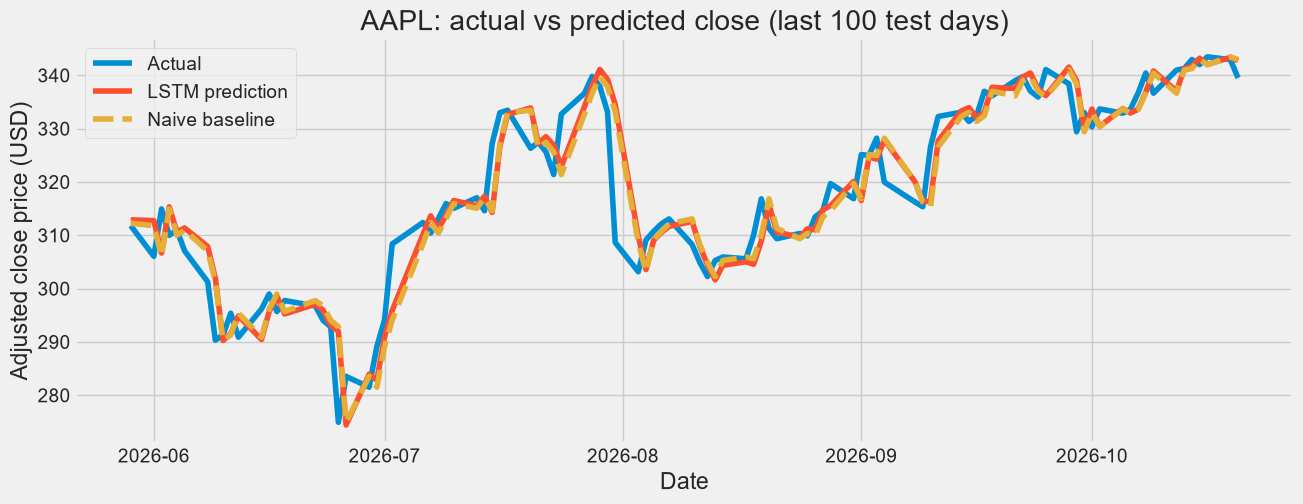

In [28]:
# Zoom in on the last 100 test days
plt.figure(figsize=(14, 5))
plt.plot(test_dates[-100:], actual[-100:], label='Actual')
plt.plot(test_dates[-100:], pred[-100:], label='LSTM prediction')
plt.plot(test_dates[-100:], naive[-100:], label='Naive baseline', linestyle='--')
plt.title(f'{TICKER}: actual vs predicted close (last 100 test days)')
plt.xlabel('Date')
plt.ylabel('Adjusted close price (USD)')
plt.legend()
plt.show()

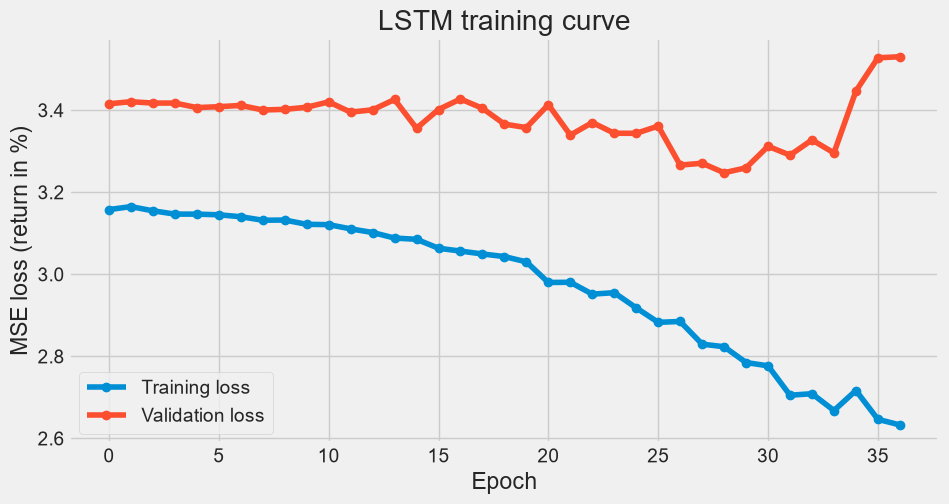

In [29]:
# Training vs validation loss per epoch
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], marker='o', label='Training loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation loss')
plt.title('LSTM training curve')
plt.xlabel('Epoch')
plt.ylabel('MSE loss (return in %)')
plt.legend()
plt.show()

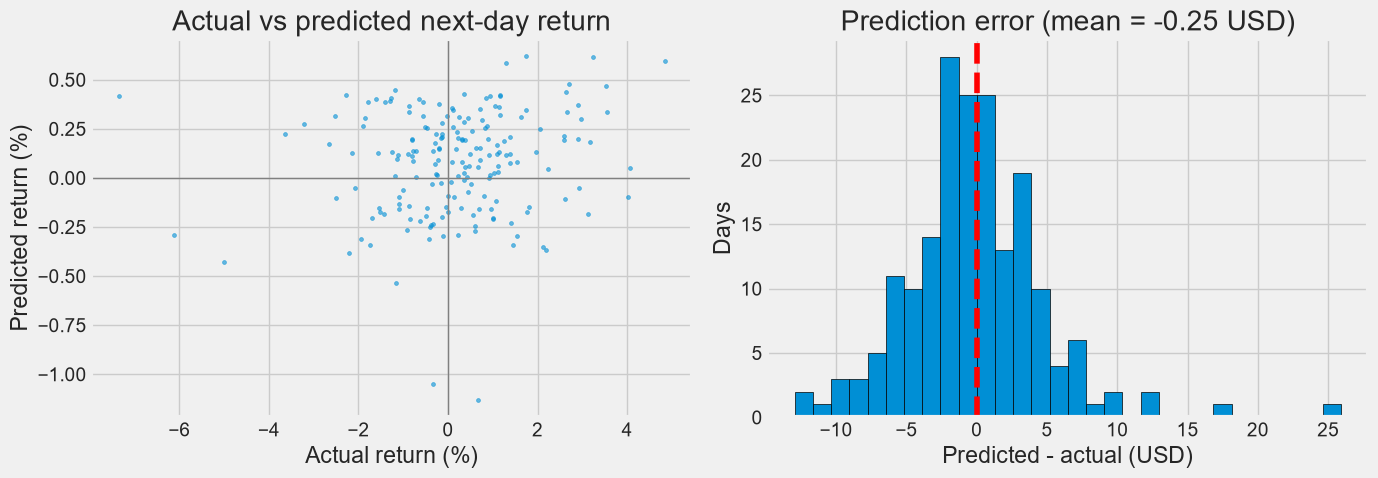

In [30]:
# Predicted vs actual daily return, and distribution of the price error
errors = pred - actual

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(true_ret * 100, pred_ret * 100, s=8, alpha=0.6)
axes[0].axhline(0, color='gray', linewidth=1)
axes[0].axvline(0, color='gray', linewidth=1)
axes[0].set_title('Actual vs predicted next-day return')
axes[0].set_xlabel('Actual return (%)')
axes[0].set_ylabel('Predicted return (%)')

axes[1].hist(errors, bins=30, edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f'Prediction error (mean = {errors.mean():.2f} USD)')
axes[1].set_xlabel('Predicted - actual (USD)')
axes[1].set_ylabel('Days')

plt.tight_layout()
plt.show()

## Limitations and next steps
- Predicting a stock's next-day move from its own price and volume history is very hard, because that information is already reflected in the price. Judge the model by the comparison with the naive and "always up" baselines in the results above, not by how close the prediction line looks on a chart.
- Only price and volume based features are used. Market-wide data (an index such as the S&P 500), news sentiment or fundamentals could be added.
- A single train/test split gives one noisy estimate. Walk-forward validation over several periods would be a fairer evaluation.
- Window size, layer sizes and dropout were not tuned.
- This is a learning project, not a trading signal.

In [31]:
# Save the trained model so it does not need retraining
model.save("lstm_model.keras")

# Summary
- Downloaded and explored market data for four tech stocks with `yfinance`, pandas, Matplotlib and Seaborn.
- Measured trend (moving averages, Bollinger Bands), daily returns, relative performance, rolling volatility, correlation between stocks, and risk vs expected return.
- Built a 2-layer LSTM (64 and 32 units, with dropout and early stopping) on 60-day windows of 5 features to predict the next-day return of AAPL.
- Avoided leakage by fitting the scaler on training data only and splitting chronologically.
- Evaluated the model against a naive "tomorrow = today" baseline and an "always up" directional baseline.